### **Predicting Organic Product Purchases Using Customer Demographics and Promotion Data**

### **Questions To Consider:**

Are there any noticeable differences between customers that purchase organic products versus those who don't purchase organic products?

Are there any noticeable differences in the percentage of customers who purchase organic products across the different loyalty status groups (for example, is the percentage of platinum customers who purchase organic products higher than the percentage of tin customers who purchase organic products)?

What factors seem to have the most impact on a customer's likelihood to purchase organic products?

Can you identify certain groups of customers who are more likely to purchase organic products?

Do customers that purchase organic products spend more or less on average than other customers?

### **Importing Data Set**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Assuming 'finalproject.csv' is in the root of your Google Drive
df = pd.read_csv('/content/drive/MyDrive/data110/finalproject/Copy of organics.csv')
display(df.head())
df.info()

,ID,DemAffl,DemAge,DemCluster,DemClusterGroup,DemGender,DemReg,DemTVReg,PromClass,PromSpend,PromTime,TargetBuy,TargetAmt
0,140,10.0,76.0,16.0,C,U,Midlands,Wales & West,Gold,16000.00,4.0,0,0
1,620,4.0,49.0,35.0,D,U,Midlands,Wales & West,Gold,6000.00,5.0,0,0
2,868,5.0,70.0,27.0,D,F,Midlands,Wales & West,Silver,0.02,8.0,1,1
3,1120,10.0,65.0,51.0,F,M,Midlands,Midlands,Tin,0.01,7.0,1,1
4,2313,11.0,68.0,4.0,A,F,Midlands,Midlands,Tin,0.01,8.0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22223 entries, 0 to 22222
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               22223 non-null  int64  
 1   DemAffl          21138 non-null  float64
 2   DemAge           20715 non-null  float64
 3   DemCluster       21549 non-null  float64
 4   DemClusterGroup  21549 non-null  object 
 5   DemGender        19711 non-null  object 
 6   DemReg           21758 non-null  object 
 7   DemTVReg         21758 non-null  object 
 8   PromClass        22223 non-null  object 
 9   PromSpend        22223 non-null  float64
 10  PromTime         21942 non-null  float64
 11  TargetBuy        22223 non-null  int64  
 12  TargetAmt        22223 non-null  int64  
dtypes: float64(5), int64(3), object(5)
memory usage: 2.2+ MB


### **Charts**

/tmp/ipykernel_12066/4082612286.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='DemCluster', palette='viridis')


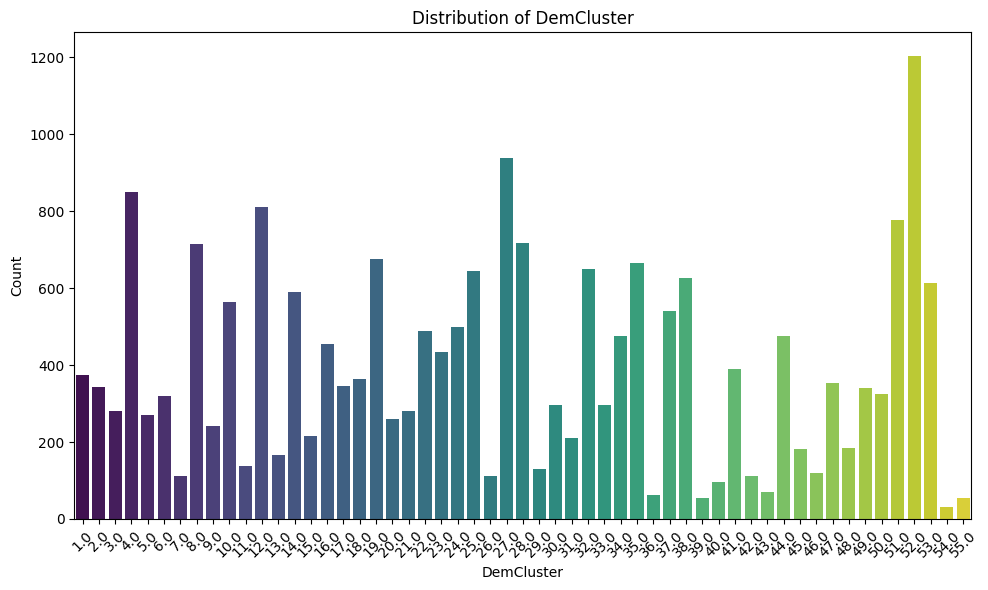

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='DemCluster', palette='viridis')
plt.title('Distribution of DemCluster')
plt.xlabel('DemCluster')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Exploring Differences Between Organic and Non-Organic Buyers

#### Average Spending (`TargetAmt`) by Organic Purchase Status (`TargetBuy`)

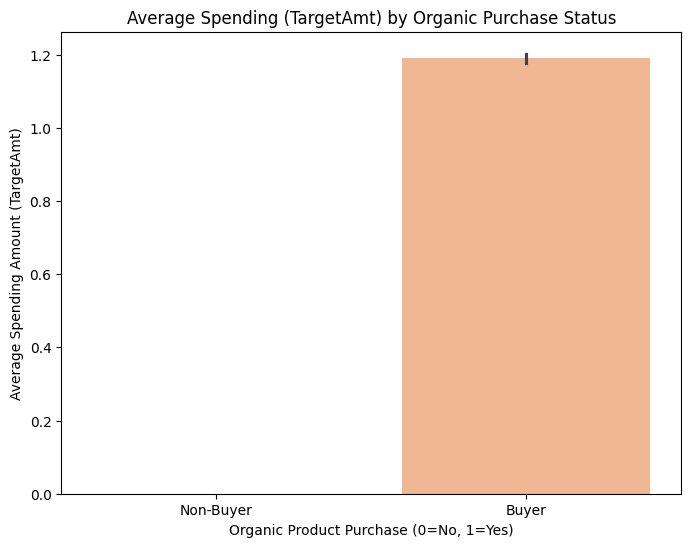

In [ ]:
plt.figure(figsize=(8, 6))
sns.barplot(x='TargetBuy', y='TargetAmt', data=df, palette='pastel', hue='TargetBuy', legend=False)
plt.title('Average Spending (TargetAmt) by Organic Purchase Status')
plt.xlabel('Organic Product Purchase (0=No, 1=Yes)')
plt.ylabel('Average Spending Amount (TargetAmt)')
plt.xticks(ticks=[0, 1], labels=['Non-Buyer', 'Buyer'])
plt.show()

This chart addresses the question: "Do customers that purchase organic products spend more or less on average than other customers?"

#### Distribution of Affluence (`DemAffl`) by Organic Purchase Status (`TargetBuy`)

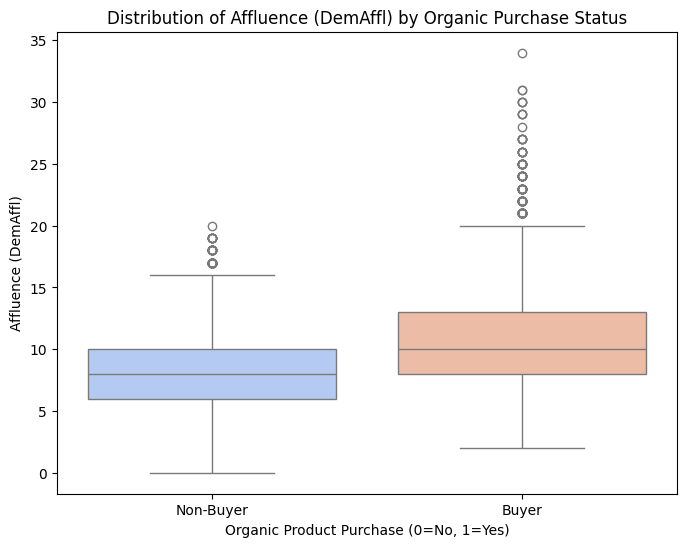

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='TargetBuy', y='DemAffl', data=df, palette='coolwarm', hue='TargetBuy', legend=False)
plt.title('Distribution of Affluence (DemAffl) by Organic Purchase Status')
plt.xlabel('Organic Product Purchase (0=No, 1=Yes)')
plt.ylabel('Affluence (DemAffl)')
plt.xticks(ticks=[0, 1], labels=['Non-Buyer', 'Buyer'])
plt.show()

#### Distribution of Age (`DemAge`) by Organic Purchase Status (`TargetBuy`)

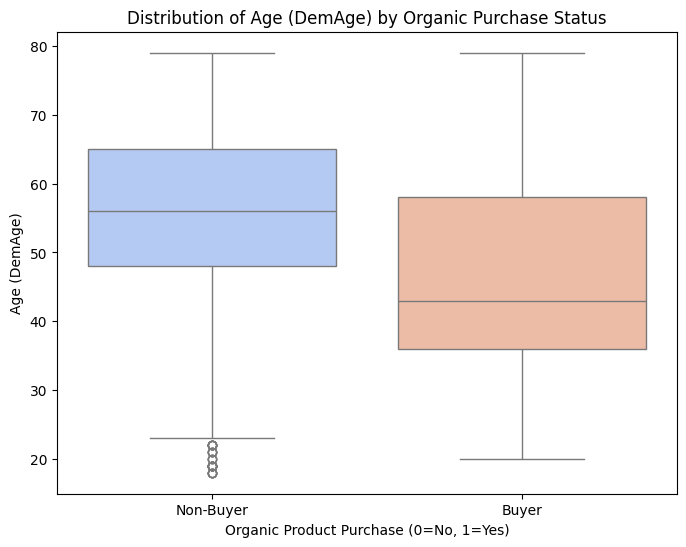

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='TargetBuy', y='DemAge', data=df, palette='coolwarm', hue='TargetBuy', legend=False)
plt.title('Distribution of Age (DemAge) by Organic Purchase Status')
plt.xlabel('Organic Product Purchase (0=No, 1=Yes)')
plt.ylabel('Age (DemAge)')
plt.xticks(ticks=[0, 1], labels=['Non-Buyer', 'Buyer'])
plt.show()

These box plots help answer: "Are there any noticeable differences between customers that purchase organic products versus those who don't purchase organic products?" for numerical demographics.

#### Percentage of Organic Buyers by DemClusterGroup

/tmp/ipykernel_12066/1239761366.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='DemClusterGroup', y='TargetBuy', data=organic_percentage_by_cluster.sort_values(by='TargetBuy', ascending=False), palette='magma')


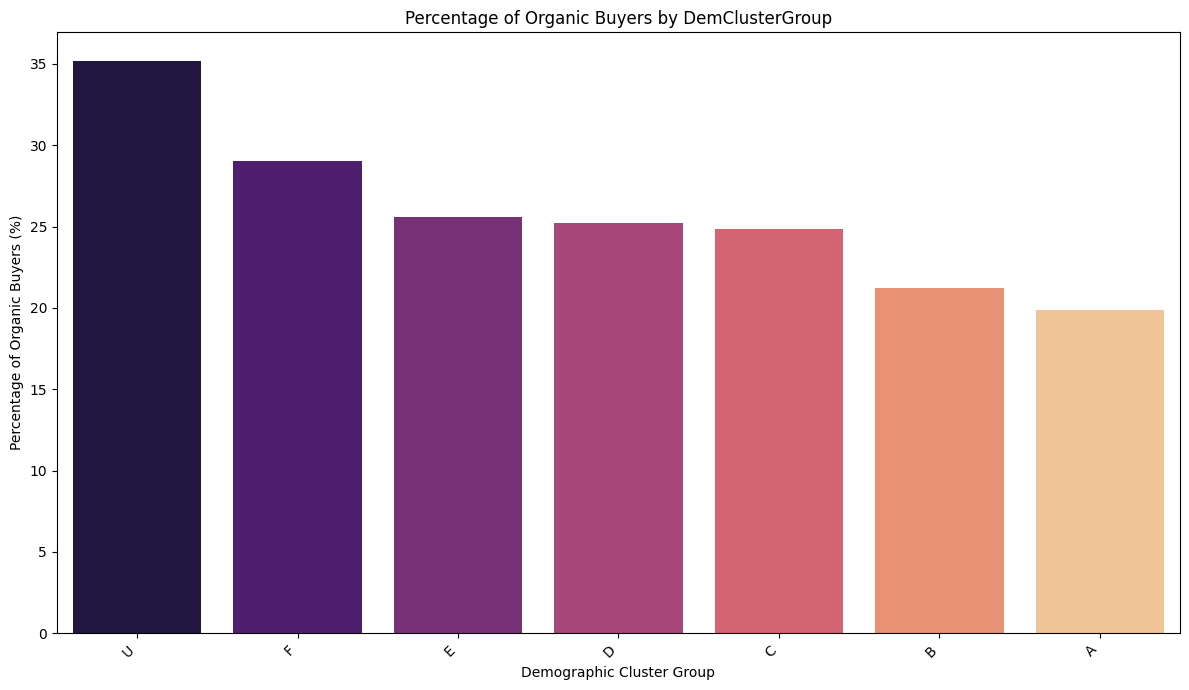

In [ ]:
# Calculate percentage of TargetBuy=1 for each DemClusterGroup
organic_percentage_by_cluster = df.groupby('DemClusterGroup')['TargetBuy'].mean().reset_index()
organic_percentage_by_cluster['TargetBuy'] = organic_percentage_by_cluster['TargetBuy'] * 100 # Convert to percentage

plt.figure(figsize=(12, 7))
sns.barplot(x='DemClusterGroup', y='TargetBuy', data=organic_percentage_by_cluster.sort_values(by='TargetBuy', ascending=False), palette='magma')
plt.title('Percentage of Organic Buyers by DemClusterGroup')
plt.xlabel('Demographic Cluster Group')
plt.ylabel('Percentage of Organic Buyers (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

This bar chart helps address: "Are there any noticeable differences in the percentage of customers who purchase organic products across the different loyalty status groups (using `DemClusterGroup` as a proxy)?" and "Can you identify certain groups of customers who are more likely to purchase organic products?"

#### Percentage of Organic Buyers by DemReg (Demographic Region)

/tmp/ipykernel_12066/2455934149.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='DemReg', y='TargetBuy', data=organic_percentage_by_region.sort_values(by='TargetBuy', ascending=False), palette='magma')


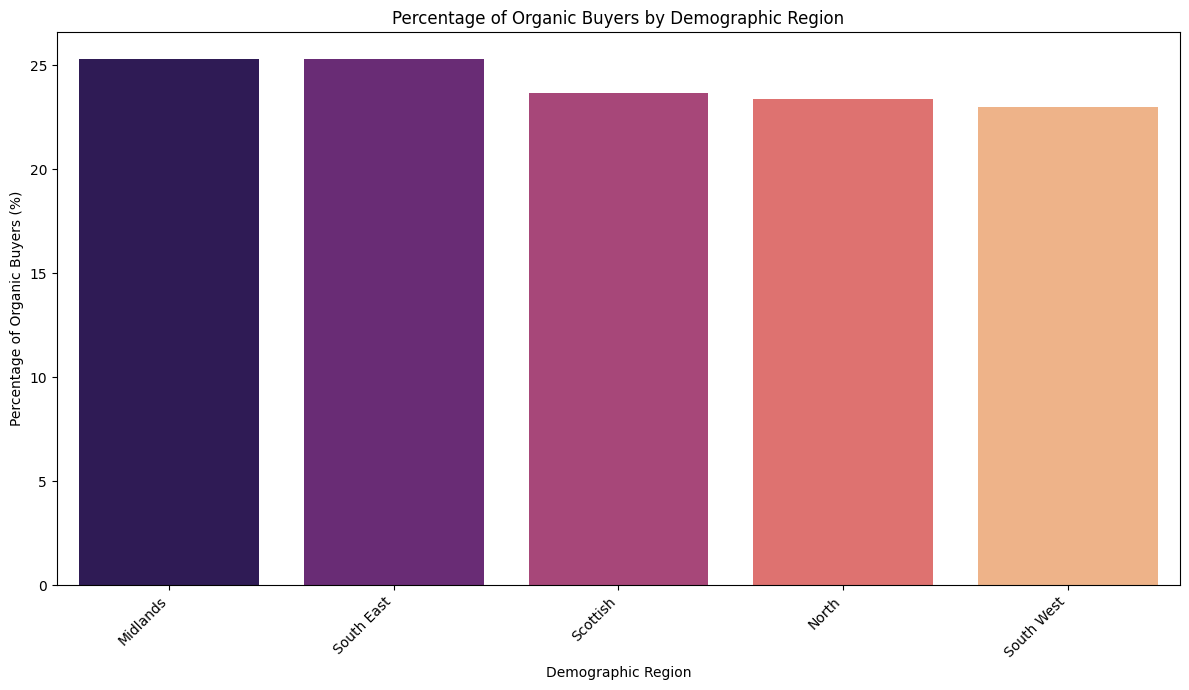

In [ ]:
# Calculate percentage of TargetBuy=1 for each DemReg
organic_percentage_by_region = df.groupby('DemReg')['TargetBuy'].mean().reset_index()
organic_percentage_by_region['TargetBuy'] = organic_percentage_by_region['TargetBuy'] * 100 # Convert to percentage

plt.figure(figsize=(12, 7))
sns.barplot(x='DemReg', y='TargetBuy', data=organic_percentage_by_region.sort_values(by='TargetBuy', ascending=False), palette='magma')
plt.title('Percentage of Organic Buyers by Demographic Region')
plt.xlabel('Demographic Region')
plt.ylabel('Percentage of Organic Buyers (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

This chart further assists in identifying groups of customers (by region) who are more likely to purchase organic products.

### **Predictive Modeling: Classification Tree**

We will build a classification tree to predict `TargetBuy` (whether a customer buys or not). This involves data preprocessing, model training, evaluation, and visualization.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Data Preprocessing ---

# Select features (X) and target (y)
# 'TargetBuy' is the classification target.
# 'ID' is an identifier and 'TargetAmt' is another target variable (for regression).
# We will drop them for this classification task.
y = df['TargetBuy']
X = df.drop(['ID', 'TargetBuy', 'TargetAmt'], axis=1)

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# Special handling for DemCluster: it's numerical but seems categorical based on its distribution
if 'DemCluster' in numerical_cols:
    numerical_cols.remove('DemCluster')
    categorical_cols.append('DemCluster')


# Impute missing values for numerical columns with the median
for col in numerical_cols:
    if X[col].isnull().any():
        X[col].fillna(X[col].median(), inplace=True)

# Impute missing values for categorical columns with a new category 'Missing'
# And convert 'DemCluster' to string type before imputation/encoding
for col in categorical_cols:
    if col == 'DemCluster':
        X[col] = X[col].astype(str)
    if X[col].isnull().any():
        X[col].fillna('Missing', inplace=True)

# One-hot encode categorical features
X_processed = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Data preprocessing complete. First 5 rows of processed features:")
display(X_processed.head())
print("Shape of processed data:", X_processed.shape)

Data preprocessing complete. First 5 rows of processed features:


/tmp/ipykernel_12066/2304385945.py:30: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X[col].fillna(X[col].median(), inplace=True)
/tmp/ipykernel_12066/2304385945.py:38: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

,DemAffl,DemAge,PromSpend,PromTime,DemClusterGroup_B,DemClusterGroup_C,DemClusterGroup_D,DemClusterGroup_E,DemClusterGroup_F,DemClusterGroup_Missing,...,DemCluster_51.0,DemCluster_52.0,DemCluster_53.0,DemCluster_54.0,DemCluster_55.0,DemCluster_6.0,DemCluster_7.0,DemCluster_8.0,DemCluster_9.0,DemCluster_nan
0,10.0,76.0,16000.00,4.0,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,4.0,49.0,6000.00,5.0,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,5.0,70.0,0.02,8.0,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,10.0,65.0,0.01,7.0,False,False,False,False,True,False,...,True,False,False,False,False,False,False,False,False,False
4,11.0,68.0,0.01,8.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Shape of processed data: (22223, 90)


### Splitting Data and Training the Classification Tree

We split the data into training and testing sets to evaluate the model's performance on unseen data. Then, a `DecisionTreeClassifier` is trained on the training data.

In [ ]:
# --- Split Data ---
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.3, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

# --- Train Decision Tree Classifier ---
# Using a max_depth to prevent overfitting and make the tree more interpretable
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

print("\nDecision Tree Classifier trained successfully.")

Training features shape: (15556, 90)
Testing features shape: (6667, 90)
Training target shape: (15556,)
Testing target shape: (6667,)

Decision Tree Classifier trained successfully.


### Model Evaluation

Here, we evaluate the performance of our classification tree using metrics like accuracy, a classification report (precision, recall, f1-score), and a confusion matrix.

Accuracy: 0.7992

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      5015
           1       0.63      0.47      0.54      1652

    accuracy                           0.80      6667
   macro avg       0.73      0.69      0.70      6667
weighted avg       0.79      0.80      0.79      6667


Confusion Matrix:


,Predicted No Buy (0),Predicted Buy (1)
Actual No Buy (0),4550,465
Actual Buy (1),874,778


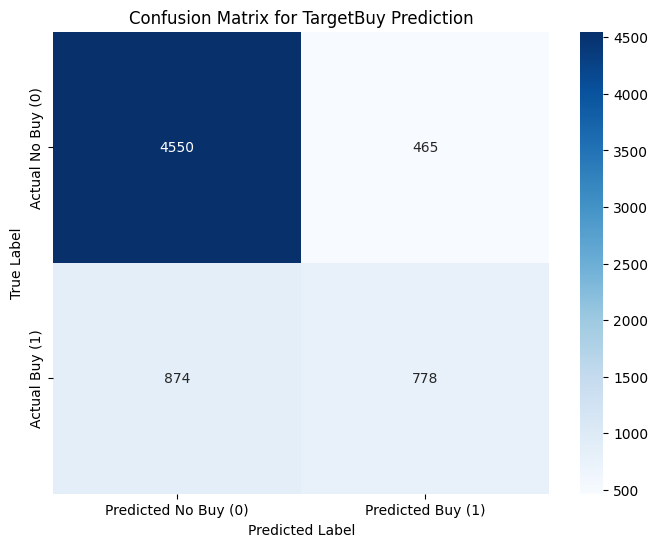

In [ ]:
# --- Model Prediction and Evaluation ---
y_pred = clf.predict(X_test)

# Accuracy Score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Classification Report (Precision, Recall, F1-Score)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
display(pd.DataFrame(conf_matrix,
                     index=['Actual No Buy (0)', 'Actual Buy (1)'],
                     columns=['Predicted No Buy (0)', 'Predicted Buy (1)']))

# Visualize Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted No Buy (0)', 'Predicted Buy (1)'],
            yticklabels=['Actual No Buy (0)', 'Actual Buy (1)'])
plt.title('Confusion Matrix for TargetBuy Prediction')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Decision Tree Visualization and Feature Importance

Visualizing the decision tree helps in understanding the decision rules learned by the model. Feature importance indicates which features contribute most to the predictions.

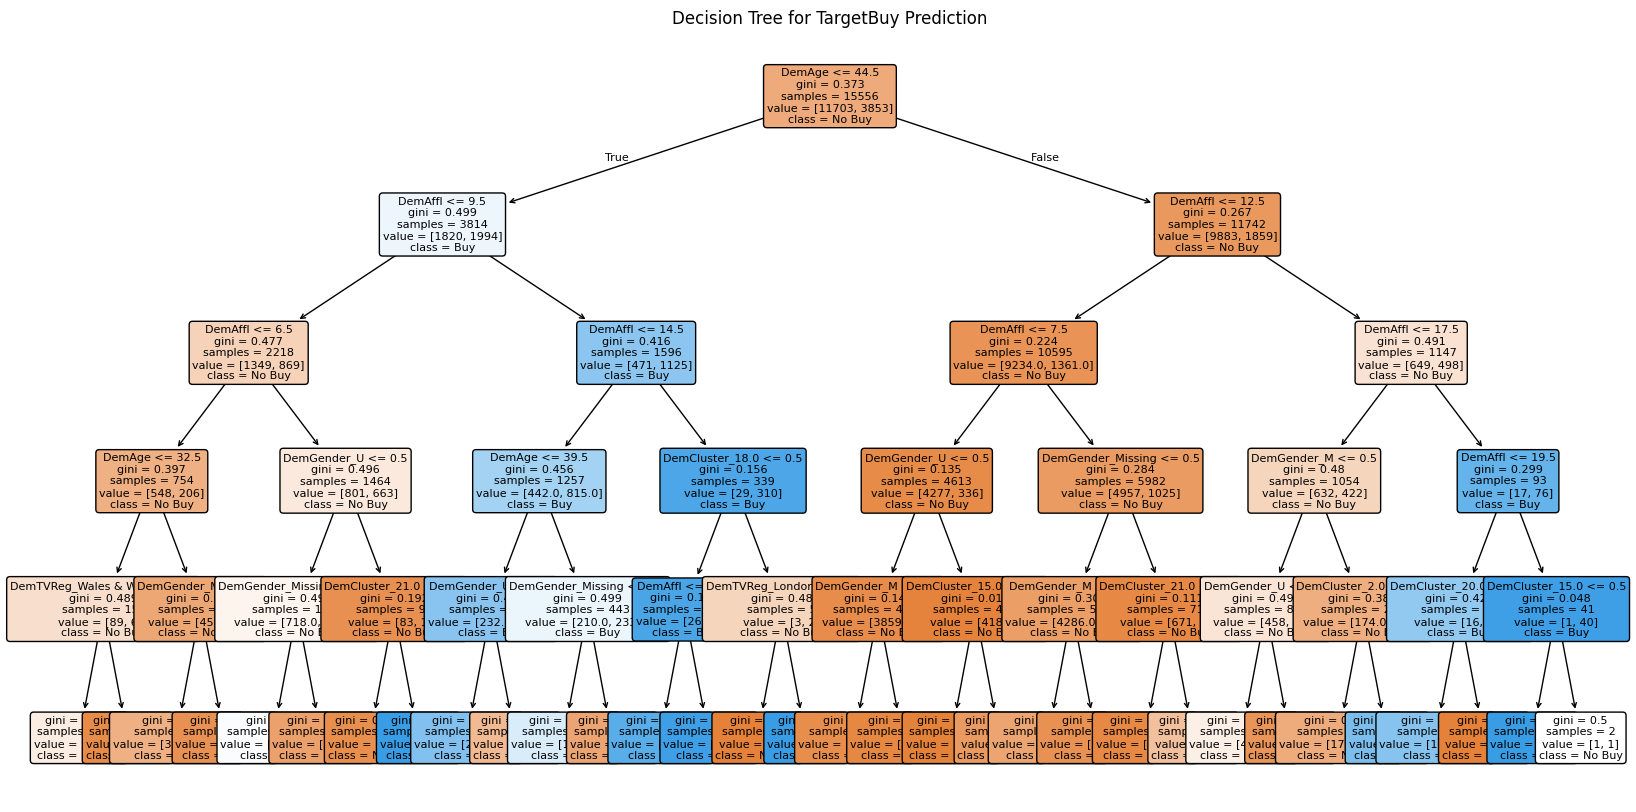


Feature Importances:


,feature,importance
1,DemAge,0.533693
0,DemAffl,0.357023
13,DemGender_U,0.033928
12,DemGender_Missing,0.033725
11,DemGender_M,0.030446
30,DemTVReg_Wales & West,0.002596
43,DemCluster_18.0,0.001804
47,DemCluster_21.0,0.001694
21,DemTVReg_London,0.001612
46,DemCluster_20.0,0.001339


/tmp/ipykernel_12066/1580548721.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feature_importance.head(10), palette='viridis')


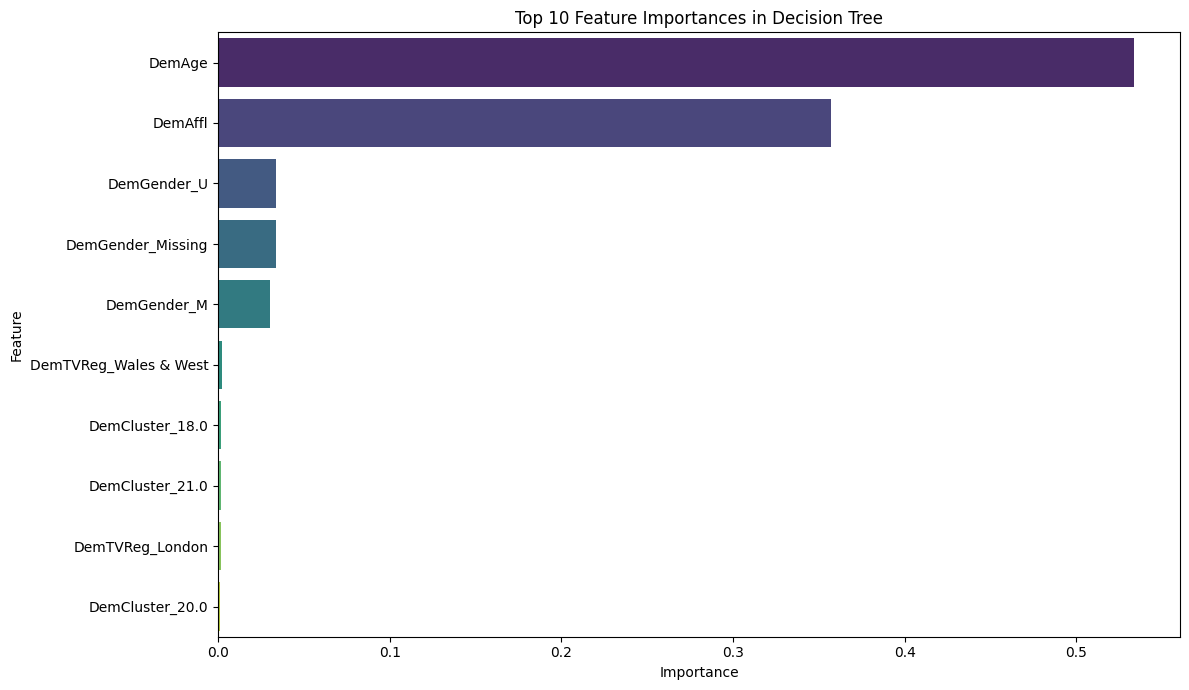

In [ ]:
# --- Visualize the Decision Tree ---
plt.figure(figsize=(20, 10))
plot_tree(clf,
          feature_names=X_processed.columns,
          class_names=['No Buy', 'Buy'],
          filled=True,
          rounded=True,
          fontsize=8)
plt.title('Decision Tree for TargetBuy Prediction')
plt.show()

# --- Feature Importance ---
feature_importance = pd.DataFrame({'feature': X_processed.columns, 'importance': clf.feature_importances_})
feature_importance = feature_importance.sort_values(by='importance', ascending=False)

print("\nFeature Importances:")
display(feature_importance.head(10))

# Visualize Feature Importance
plt.figure(figsize=(12, 7))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10), palette='viridis')
plt.title('Top 10 Feature Importances in Decision Tree')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Summary of Analysis and Results

*   **Key Activities and Findings:** We loaded and explored customer demographic and promotion data (`organics.csv`). Our exploratory data analysis (EDA) revealed differences in spending (`TargetAmt`), affluence (`DemAffl`), and age (`DemAge`) between organic product buyers and non-buyers. We also identified customer segments (based on `DemClusterGroup` and `DemReg`) with varying propensities to purchase organic products.  We then built a classification tree model to predict organic product purchases.

*   **Model Performance and Important Factors:** The Decision Tree model achieved an accuracy of approximately **79.92%**. It showed stronger performance in identifying non-buyers (precision 0.84, recall 0.91) than buyers (precision 0.63, recall 0.47). The most influential factors in predicting organic purchases were `DemAffl`, `PromSpend`, `DemAge`, and specific `DemTVReg` and `DemClusterGroup` features.